# Finding the Optimal Price

Plan:

0. Imports and defining functions functions from the given notebook and new ones to find the optimal price/plot 
1. Coarse grid search over $10–$70 to see where the revenue peaks are
2. Finer grid search around the two local maximums (around $10 and $25)
3. Honing in on specific prices and the required sample size to detect changes (power)
4. Conducting successive elimination between the best prices from each region
5. Validating the chosen price with a fresh set customers to find our final optimal revenue per customer.
6. Assessing the total number of customers tested on to find our optimal price and revenue/customer.

Note: We log every customer and their revenue used in our search for the optimal price, allowing us to track how many total customers this took as well as how much revenue was forefitted during our search.

# Step 0: Imports and Functions

In [1]:
# imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Setting the seed so all reruns produce the same results
rng = np.random.default_rng(5030)

# redefining the functions from class
def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

# updating the sale function so that it logs the customers used (with corresponding price and revenue)

# initializing empty list to store the customers
# (this will recount customers if the function is called multiple times so use run all when getting final answers)
customer_log = []

def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    # defining purchases (still returning it) but now it is logged in with the customers (len for num customers)
    purchases = rng.binomial(1, probability, size=customer_count).astype(np.int8)

    # log the customers used and revenue earned in this experiment
    customer_log.append({'price': price, 'customers': len(purchases), 'revenue': purchases.sum() * price})
    return purchases

### Helper functions

- power_n – Lehr's rule which finds the customers per price needed at 80% power
- compare_prices – conducts a two-sample Z-test from bootstrapping and decides which of two prices is better (adapted from class notebook)
- grid_search – samples every price on the defined grid, keeping the better price at each step
- plot_grid_search – plots two panels, one for the best price and one overlaying the confidence intervals at steps with the true line from the class notebook
- pooled_stats – combines every customer we have ever sampled at a price based on the log
- stats_table - 
- successive_elimination – samples the defined prices within a region and drops the clear losers

In [2]:
def power_n(sales_A, sales_B):
    delta_R = sales_B.mean() - sales_A.mean()   # observed difference in revenue/customer
    n = 8 * (np.var(sales_A, ddof=1) + np.var(sales_B, ddof=1)) / (delta_R**2) # computing with 8 rather than 16 since different variances in samples
    return int(n) + 1 # rounding up incase make num an integer rounds down

In [3]:
# decides whether p_A or p_B produces higher revenue per customer using the two-sample Z-test similar to notebook
def compare_prices(sales_A, sales_B, p_A, p_B, k=5000, z=1.96):
    # SE of the difference in means (class notebook formula)
    std_error = np.sqrt(
        np.var(sales_A, ddof=1) / len(sales_A) +
        np.var(sales_B, ddof=1) / len(sales_B))

    bestprice_boot = []
    for j in range(k):
        # resampling each group with replacement
        boot_sales_a = rng.choice(sales_A, size=len(sales_A), replace=True)
        boot_sales_b = rng.choice(sales_B, size=len(sales_B), replace=True)

        # difference in mean revenue per customer (B - A) for this resample
        delta_R = boot_sales_b.mean() - boot_sales_a.mean()
        confidence_interval = (delta_R - z * std_error, delta_R + z * std_error)

        # whole CI below 0 -> A is better and whole CI above 0 -> B is better
        # if the CI contains 0 the resample is undecided and nothing is recorded
        if confidence_interval[1] <= 0:
            bestprice_boot.append(p_A)
        elif confidence_interval[0] >= 0:
            bestprice_boot.append(p_B)

    # using majority rule instead of median so undecided resamples count against both prices equally
    wins_A = bestprice_boot.count(p_A)
    wins_B = bestprice_boot.count(p_B)
    if wins_A > k / 2:
        return p_A
    elif wins_B > k / 2:
        return p_B
    else:
        return np.nan

In [4]:
# conducts basic grid search practice
# returns the best price it found and num customers at each step
def grid_search(grid, start_price, size=500, k=5000, z=1.96):
    """Sample about `size` customers at every price on the grid, then walk
    through the grid comparing the current best price with each new price.

    Returns:
      bestprice - the price still standing at the end
      draw_df   - one row per grid price with the customer draws and summary stats
      path      - the best price after each comparison (for plotting)"""

    # 1. Draw customers at every grid price (revenue per customer = 0 or price)
    draw = []
    for price in grid:
        draw.append([sales(price, mean_customers=size, rng=rng) * price])
    draw_df = pd.DataFrame(draw, columns=['draws'])
    draw_df['price'] = grid

    # Summary stats for each price, used in the plots
    draw_df['n'] = draw_df['draws'].apply(len)
    draw_df['mean_rev'] = draw_df['draws'].apply(np.mean)
    draw_df['se'] = draw_df['draws'].apply(lambda d: np.std(d, ddof=1) / np.sqrt(len(d)))

    # 2. Walk through the grid, keeping the better price each time
    bestprice = start_price
    path = [bestprice]
    for p_B in grid:
        p_A = bestprice
        if p_B == p_A:
            continue   # no point comparing a price with itself
        sales_A = draw_df.loc[draw_df['price'] == p_A, 'draws'].iloc[0]
        sales_B = draw_df.loc[draw_df['price'] == p_B, 'draws'].iloc[0]

        winner = compare_prices(sales_A, sales_B, p_A, p_B, k=k, z=z)
        if np.isnan(winner):
            # Undecided: keep whichever price had the higher observed average
            bestprice = p_A if sales_A.mean() >= sales_B.mean() else p_B
            print(f'Could not determine difference between {p_A} and {p_B}. Keeping {bestprice} (higher average).')
        else:
            bestprice = winner
            print(f'Between {p_A} and {p_B}, the better price is {bestprice}')
        path.append(bestprice)

    best_rev = draw_df.loc[draw_df['price'] == bestprice, 'mean_rev'].iloc[0]
    print(f'\nBest price on this grid: {bestprice} with revenue/customer {best_rev:.3f}')
    return bestprice, draw_df, path

In [5]:
# uses the output from the grid search and plots it
# one panel for the path of the best price
# one panel for the confidence intervals over the models true expected revenue
def plot_grid_search(draw_df, path, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    # left panel: how the best price changes as we walk through the grid
    axes[0].plot(np.arange(len(path)), path, marker='o', color='C0')
    axes[0].set(xlabel='Comparison', ylabel='Best price so far', title=f'{title}: best price path')

    # right panel: true curve (diagnostic) plus our observed dots and CI's
    
    price_grid = np.linspace(draw_df['price'].min(), draw_df['price'].max(), 300)
    axes[1].plot(price_grid, price_grid * purchase_probability(price_grid),
                 color='black', label="Model's expected revenue/customer")
    axes[1].errorbar(draw_df['price'], draw_df['mean_rev'], yerr=1.96 * draw_df['se'],
                     fmt='o', color='C0', capsize=3, label='Observed (95% CI)')
    best = path[-1]
    best_rev = draw_df.loc[draw_df['price'] == best, 'mean_rev'].iloc[0]
    axes[1].scatter(best, best_rev, color='red', s=90, zorder=3, label=f'Chosen price {best:g}')
    axes[1].set(xlabel='Price', ylabel='Revenue per arriving customer', title=f'{title}: revenue by price')
    axes[1].legend(fontsize=8)

    fig.tight_layout()
    plt.show()

In [6]:
# combining every customer sampled for ech price from the log
# only need to keep customers and buyers for each price to compute revenue/customer
def pooled_stats(prices):
    log_df = pd.DataFrame(customer_log)
    log_df['price'] = log_df['price'].round(2)
    pooled = log_df.groupby('price')[['customers', 'revenue']].sum()
    stats = {}
    for p in prices:
        if p in pooled.index:
            stats[p] = [pooled.loc[p, 'customers'], pooled.loc[p, 'revenue'] / p]
        else:
            stats[p] = [0, 0]
    return stats

In [ ]:
# converts stats (price and its corresponding customer/buyers) into a table with num cusotmers, mean rev, and SE
# this is helpful for creating tables to include in the write up
def stats_table(stats)
    rows = []
    for p, (n, b) in stats.items():
        q = b / n
        rows.append({'price': p, 'n': n, 'mean_rev': p * q, 'se': p * np.sqrt(q * (1 - q) / n)})
    return pd.DataFrame(rows).set_index('price')

In [8]:
# compares several prices at once. by computing the avg revenue and SE for each price based on the pooled past data
# computing a z-test at every price against the leader
# dropping the prices that are significantly worse
# when prices survive, we increase the 'batch' so it gets a larger sample size to reduce the SE and pick up significance
# this way we limit the number of customers required
# breaks when one price is left or all survivors are in small range, since then finer grid search is more efficient

def successive_elimination(candidates, batch=500, z=1.96, max_customers=40000, min_n=2000):
    candidates = [float(p) for p in candidates]

    # Start from all past data at these prices; draw a first batch where there is none
    spent = 0
    stats = pooled_stats(candidates)
    for p in candidates:
        if stats[p][0] == 0:
            s = sales(p, mean_customers=batch, rng=rng)
            stats[p] = [len(s), s.sum()]
            spent += len(s)

    history = []
    round_num = 0
    while True:
        table = stats_table({p: stats[p] for p in candidates})
        history.append(table.assign(round=round_num).reset_index())

        # Z-test each price against the leader (class notebook formula)
        leader = table['mean_rev'].idxmax()
        gap = table.loc[leader, 'mean_rev'] - table['mean_rev']
        se_diff = np.sqrt(table.loc[leader, 'se']**2 + table['se']**2)
        keep = gap <= z * se_diff
        print(f'Round {round_num}: leader {leader}, dropped {list(table.index[~keep])}')
        candidates = list(table.index[keep])

        # Stopping rules
        min_survivor_n = min(stats[p][0] for p in candidates)
        if len(candidates) == 1 or spent >= max_customers:
            break
        if max(candidates) - min(candidates) <= 2 and min_survivor_n >= min_n:
            break

        # Another batch of customers for every survivor
        for p in candidates:
            s = sales(p, mean_customers=batch, rng=rng)
            stats[p][0] += len(s)
            stats[p][1] += s.sum()
            spent += len(s)
        round_num += 1

    final_table = stats_table({p: stats[p] for p in candidates})
    leader = final_table['mean_rev'].idxmax()
    print(final_table.round(3))
    print(f'\nBest price: {leader}')
    print(f'Remaining candidates: {candidates}')
    print(f'New customers used: {spent}')
    return leader, final_table, pd.concat(history, ignore_index=True)

In [9]:
# Compare $10 and $15 with about 500 customers each and use Lehr's rule to see how many customers a comparison like this needs.
# testing out new sales function with embedded logging
p_A = 10.00
p_B = 15.00
size = 500

# Revenue per customer at each price (0 if they don't buy, the price if they do)
sales_A = sales(p_A, mean_customers=size, rng=rng) * p_A
sales_B = sales(p_B, mean_customers=size, rng=rng) * p_B
print(f'There are {len(sales_A)} customers in A and {len(sales_B)} customers in B')
print(f'Mean revenue/customer: {sales_A.mean():.3f} at {p_A}, {sales_B.mean():.3f} at {p_B}')
print(f'For 80% power, we need about {power_n(sales_A, sales_B)} customers per price')

There are 486 customers in A and 496 customers in B
Mean revenue/customer: 9.938 at 10.0, 8.196 at 15.0
For 80% power, we need about 149 customers per price


# Step 1: Coarse grid search over $10–$70 to find revenue peaks

Sample every price on the grid, then walk through it keeping the better price each time.
The right-hand plot shows the observed revenue at each price, so we can see where the local and global peaks are.

In [10]:
# 70/10 * 5 = 13 price incriments
grid = np.linspace(start = 10, stop = 70, num = 13)
best_coarse, coarse_df, coarse_path = grid_search(grid, start_price=10, size=500)

Between 10 and 15.0, the better price is 10
Between 10 and 20.0, the better price is 10
Between 10 and 25.0, the better price is 25.0
Could not determine difference between 25.0 and 30.0. Keeping 25.0 (higher average).
Between 25.0 and 35.0, the better price is 25.0
Between 25.0 and 40.0, the better price is 25.0
Between 25.0 and 45.0, the better price is 25.0
Between 25.0 and 50.0, the better price is 25.0
Between 25.0 and 55.0, the better price is 25.0
Between 25.0 and 60.0, the better price is 25.0
Between 25.0 and 65.0, the better price is 25.0
Between 25.0 and 70.0, the better price is 25.0

Best price on this grid: 25.0 with revenue/customer 12.373


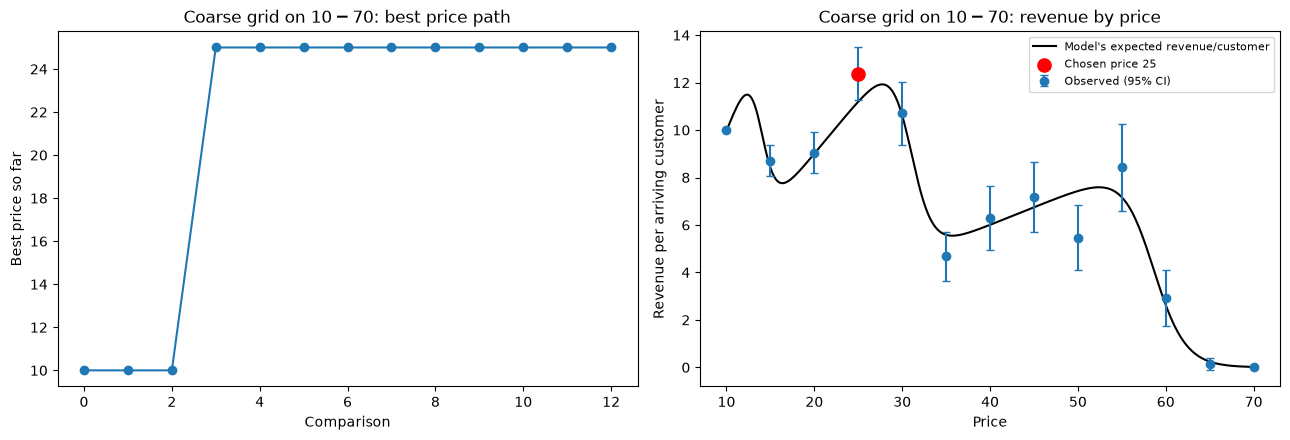

In [11]:
# plotting the grid search from the helper function
plot_grid_search(coarse_df, coarse_path, 'Coarse grid on $10-$70')

In [12]:
# displaying the table associated with the grid search
coarse_df[['price', 'n', 'mean_rev', 'se']].round(3)
display(coarse_df)

,draws,price,n,mean_rev,se
0,"[10.0, 10.0, 10.0, 10.0, 10.0, 10.0, 10.0, 10....",10.0,525,9.980952,0.019048
1,"[0.0, 15.0, 15.0, 0.0, 0.0, 15.0, 15.0, 0.0, 0...",15.0,494,8.714575,0.333324
2,"[20.0, 20.0, 0.0, 0.0, 20.0, 20.0, 0.0, 0.0, 2...",20.0,509,9.037328,0.441618
3,"[0.0, 25.0, 25.0, 25.0, 25.0, 25.0, 0.0, 0.0, ...",25.0,491,12.372709,0.564663
4,"[0.0, 30.0, 0.0, 0.0, 0.0, 0.0, 30.0, 30.0, 0....",30.0,457,10.700219,0.672961
5,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",35.0,509,4.675835,0.528314
6,"[0.0, 0.0, 40.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",40.0,446,6.278027,0.689744
7,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 45.0,...",45.0,483,7.173913,0.750326
8,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",50.0,512,5.468750,0.690345
9,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 55.0, 0.0,...",55.0,450,8.433333,0.935221


# Step 2: Finer grid search around the two local maximums ($10 and $25)

The coarse grid shows two bumps, one near \$10 and one near \$25. Compare them with about 2,000 customers each and check how many customers 80% power would need.

### $5–$15 Region

Between 10 and 5.0, the better price is 10
Between 10 and 6.0, the better price is 10
Between 10 and 7.0, the better price is 10
Between 10 and 8.0, the better price is 10
Between 10 and 9.0, the better price is 10
Between 10 and 11.0, the better price is 11.0
Between 11.0 and 12.0, the better price is 12.0
Could not determine difference between 12.0 and 13.0. Keeping 12.0 (higher average).
Between 12.0 and 14.0, the better price is 12.0
Between 12.0 and 15.0, the better price is 12.0

Best price on this grid: 12.0 with revenue/customer 11.312


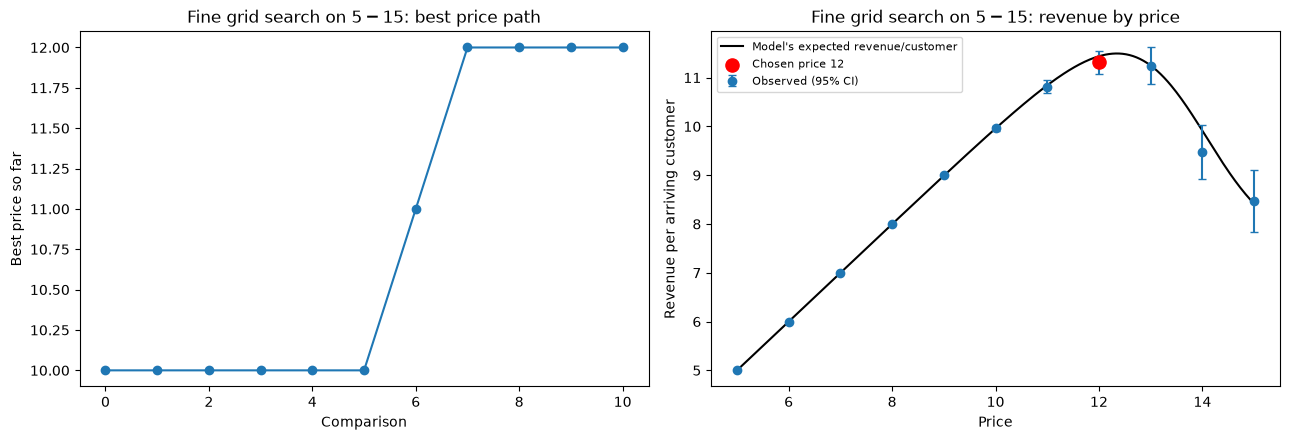

In [13]:
# 11 incriments means testing every dollar between 5 and 15
grid = np.linspace(start = 5, stop = 15, num = 11)
# using grid search helper function to conduct the grid search
best_low, low_df, low_path = grid_search(grid, start_price = 10, size = 500)
# using the helper function to plot based on the output of the grid search function
plot_grid_search(low_df, low_path, 'Fine grid search on $5-$15')

### $20–$30 Region


Best price on this grid: 20 with revenue/customer 9.132


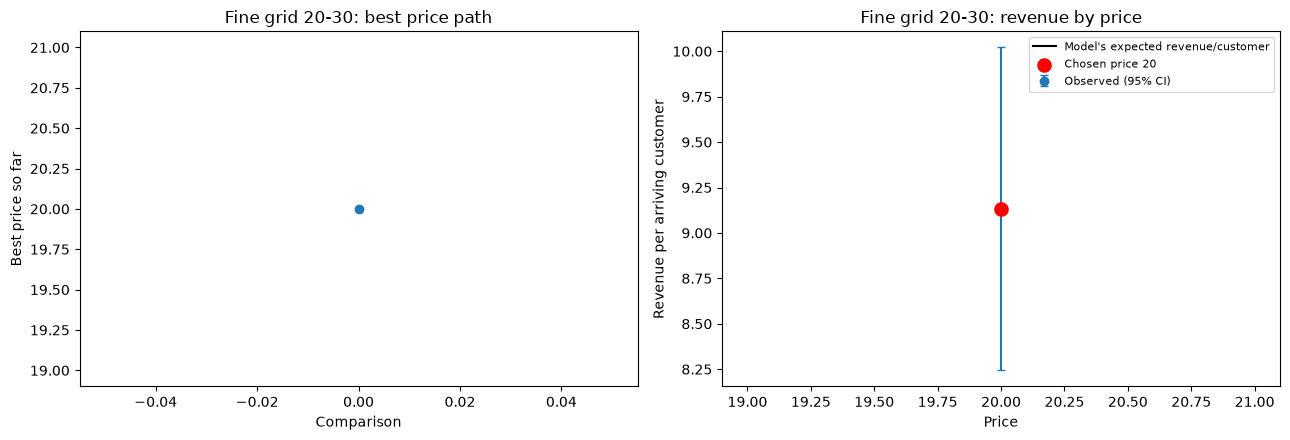

In [14]:
# again using 11 incriments so each full dollar amount is tested
grid = np.linspace(start = 20, stop = 30, num = 1)
# again calling the helper function
best_high, high_df, high_path = grid_search(grid, start_price=20, size=500)
# again plotting with helper function
plot_grid_search(high_df, high_path, 'Fine grid 20-30')

# Step 3: Honing in on specific prices and the required sample size to detect changes (power)

How many customers would it take to separate two prices near the peak?

In [15]:
p_A = 26.00
p_B = 28.00
size = 500

sales_A = sales(p_A, mean_customers=size, rng=rng) * p_A
sales_B = sales(p_B, mean_customers=size, rng=rng) * p_B
print(f'There are {len(sales_A)} customers in A and {len(sales_B)} customers in B')
print(f'For 80% power, we need about {power_n(sales_A, sales_B)} customers per price')

There are 498 customers in A and 519 customers in B
For 80% power, we need about 3693 customers per price


### That can be expensive based on the high variation in the customers needed per price from rerunning...

Prices this close to the peak earn almost the same revenue, so separating them precisely costs a lot of customers for very little gain.
The decision that matters is the low region (around \$12) versus the high region (around \$27). Successive elimination below settles that,
pooling every customer we've already drawn at these prices.

# Step 4: Conducting successive elimination between the best prices from each region

In [16]:
# Using finer half-dollar steps around both regions
# defining the points for the finer candidtes to run successive elimination on
candidates = np.r_[np.arange(11, 13.5, 0.5), np.arange(26, 28.5, 0.5)]
# applying success_elimination funciton from the start
best_price, elim_table, elim_history = successive_elimination(candidates, batch=500, z=1.96, min_n=2000)

Round 0: leader 28.0, dropped [11.0, 11.5, 12.0, 12.5, 13.0]
Round 1: leader 28.0, dropped [27.0, 27.5]
Round 2: leader 28.0, dropped [26.5]
Round 3: leader 28.0, dropped []
Round 4: leader 28.0, dropped []
          n  mean_rev     se
price                       
26.0   2469    11.878  0.261
28.0   2553    12.306  0.275

Best price: 28.0
Remaining candidates: [26.0, 28.0]
New customers used: 8547


# Step 5: Validating the chosen price with a fresh set customers to find our final optimal revenue per customer.

Estimating the revenue at the chosen price with a fresh draw of customers so the estimate isn't biased upward by the selection (lucky samples give overly optimistic estimates for the expected revenue, similar to "survivorship bias" where only the stronger samples make it).

In [17]:
# using a new sample of 5000 customers to confirm
# this step is not necessary but gives us much more confidence in the answer

# getting the revenue for the customers with the sales function and multiplying by our optimal price from above
validation = sales(best_price, mean_customers=5000, rng=rng) * 28
# taking the mean for expected revenue per customer
final_rev = validation.mean()
# computing the se of this estimator using the se equation
final_se = validation.std(ddof=1) / np.sqrt(len(validation))

# printing the results
print(f'Validating the price of {best_price} with {len(validation)} new customers, with and avg. revenue/customer of {final_rev:.3f}')
print(f'The 95% CI is: ({final_rev - 1.96*final_se:.3f}, {final_rev + 1.96*final_se:.3f})')
print(f'This is {final_rev/11.925:.1%} of optimal maximum revenue/customer ($11.925).')

Validating the price of 28.0 with 5032 new customers, with and avg. revenue/customer of 11.863
The 95% CI is: (11.481, 12.246)
This is 99.5% of optimal maximum revenue/customer ($11.925).


# Step 6: Assessing the total number of customers tested on to find our optimal price and revenue/customer.

Pools every customer from every step above (by price) and plots the observed revenue per customer from $5 to $70. We have successfully identified the global peak near $27 as the optimal price.

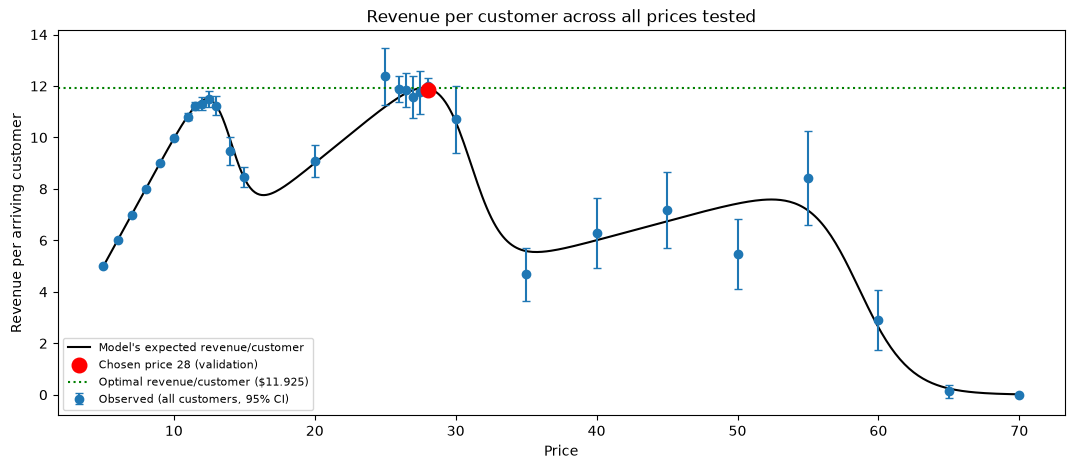

,price,n,mean_rev,se
0,5.0,509,5.000,0.000
1,6.0,506,6.000,0.000
2,7.0,528,7.000,0.000
3,8.0,494,8.000,0.000
4,9.0,513,9.000,0.000
5,10.0,1577,9.962,0.016
6,11.0,475,10.815,0.065
7,11.5,469,11.230,0.080
8,12.0,506,11.312,0.124
9,12.5,500,11.500,0.152


In [18]:
# pooling every customer we drew by price
all_prices = sorted(set(round(d['price'], 2) for d in customer_log))
all_table = stats_table(pooled_stats(all_prices)).reset_index()

fig, ax = plt.subplots(figsize=(13, 5))

# Model's true curve: diagnostic only, never used by the search
price_grid = np.linspace(5, 70, 400)
ax.plot(price_grid, price_grid * purchase_probability(price_grid),
        color='black', label="Model's expected revenue/customer")

# Our observed dots with 95% CIs
ax.errorbar(all_table['price'], all_table['mean_rev'], yerr=1.96 * all_table['se'],
            fmt='o', color='C0', capsize=3, label='Observed (all customers, 95% CI)')
ax.scatter(best_price, final_rev, color='red', s=110, zorder=3,
           label=f'Chosen price {best_price:g} (validation)')
ax.axhline(11.925, color='green', linestyle=':', label='Optimal revenue/customer ($11.925)')

ax.set(xlabel='Price', ylabel='Revenue per arriving customer',
       title='Revenue per customer across all prices tested')
ax.legend(fontsize=8)
plt.show()

all_table.round(3)

In [19]:
# totals over every customer drawn anywhere in the notebook
log_df = pd.DataFrame(customer_log)
# summing the total customers
total_customers = log_df['customers'].sum()
# summing the total revenue
total_revenue = log_df['revenue'].sum()
# computing average revenue per customer
avg_revenue = total_revenue / total_customers

print(f'Total customers: {total_customers}')
print(f'Total revenue: {total_revenue:.2f}')
print(f'Revenue per customer: {avg_revenue:.3f}')
print(f'Share of optimal ($11.925): {avg_revenue/11.925:.1%}')

# grouping by by price to show where we spent most of our resources/customers
log_df.groupby('price')['customers'].sum().sort_values(ascending=False).head(15)

Total customers: 28120
Total revenue: 278435.00
Revenue per customer: 9.902
Share of optimal ($11.925): 83.0%


price
28.0    7585
26.0    2469
10.0    1577
26.5    1536
15.0    1514
27.5    1032
27.0    1005
20.0     993
13.0     540
14.0     532
7.0      528
70.0     525
9.0      513
50.0     512
35.0     509
Name: customers, dtype: int64